In [1]:
import os
print(os.getcwd())
print(os.listdir("."))

C:\Users\ferra\MIC\2n_any_UdG\CADx\Project\Project-1-CAD\notebooks
['baseline-classification.ipynb', 'binary-results-summary.ipynb', 'data-analysis.ipynb', 'exp0123-feature-selection.ipynb', 'exp4-no-hair-removal.ipynb', 'exp5-binary-ensembling.ipynb', 'exp6-full-train.ipynb', 'exp78-new-features.ipynb', 'feature-extraction.ipynb', 'multiclass-augmentation.ipynb', 'multiclass-baseline.ipynb', 'multiclass-regional.ipynb', 'preprocessing.ipynb']


In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
from PIL import Image
from src.config import *
import numpy as np
from src.utils import *

In [3]:
LABEL_MAP = {"nevus": 0, "others": 1}

records = []
for folder, label in LABEL_MAP.items():
    for img_path in sorted((BINARY_TRAIN_DIR / folder).glob("*.jpg")):
        with Image.open(img_path) as img:
            records.append({
                "filename": img_path.name,
                "class": folder,
                "label": label,
                "subtype": img_path.stem.rstrip("0123456789"),  # e.g. 'nev', 'ack', 'bcc'
                "width": img.width,
                "height": img.height,
            })

meta_data = pd.DataFrame(records)
meta_data.head()

,filename,class,label,subtype,width,height
0,nev00001.jpg,nevus,0,nev,600,450
1,nev00002.jpg,nevus,0,nev,1024,1024
2,nev00003.jpg,nevus,0,nev,1024,1024
3,nev00004.jpg,nevus,0,nev,600,450
4,nev00005.jpg,nevus,0,nev,600,450


In [4]:
print("Class counts:\n", meta_data["class"].value_counts(), "\n")

meta_data["size"] = meta_data["width"].astype(str) + "x" + meta_data["height"].astype(str)
print("Number of distinct sizes:", meta_data["size"].nunique())
print(meta_data["size"].value_counts().head(10), "\n")

print(meta_data[["width", "height"]].describe())

Class counts:
 class
nevus     7725
others    7470
Name: count, dtype: int64 

Number of distinct sizes: 73
size
1024x1024    7452
600x450      6024
1024x680      681
1024x768      462
1024x682       99
1024x685       93
1024x681       47
1024x764       44
1024x679       34
919x802        33
Name: count, dtype: int64 

              width        height
count  15195.000000  15195.000000
mean     854.632971    760.666206
std      207.044048    269.914304
min      576.000000    450.000000
25%      600.000000    450.000000
50%     1024.000000    768.000000
75%     1024.000000   1024.000000
max     1024.000000   1024.000000


In [5]:
gt = meta_data[["filename", "label"]]
gt.to_csv(BINARY_GT_TRAIN_CSV, index=False)
print(f"Saved {len(gt)} rows to {BINARY_GT_TRAIN_CSV}")

Saved 15195 rows to C:\Users\ferra\MIC\2n_any_UdG\CADx\Project\Project-1-CAD\dataset\binary\train_ground_truth.csv


In [6]:
pd.crosstab(meta_data["size"], meta_data["class"]).sort_values("nevus", ascending=False).head(10)

class,nevus,others
size,,
600x450,4045,1979
1024x1024,2519,4933
1024x680,411,270
1024x768,351,111
1024x682,87,12
1024x685,58,35
1024x681,35,12
767x576,27,6
1024x679,25,9


seed: 124


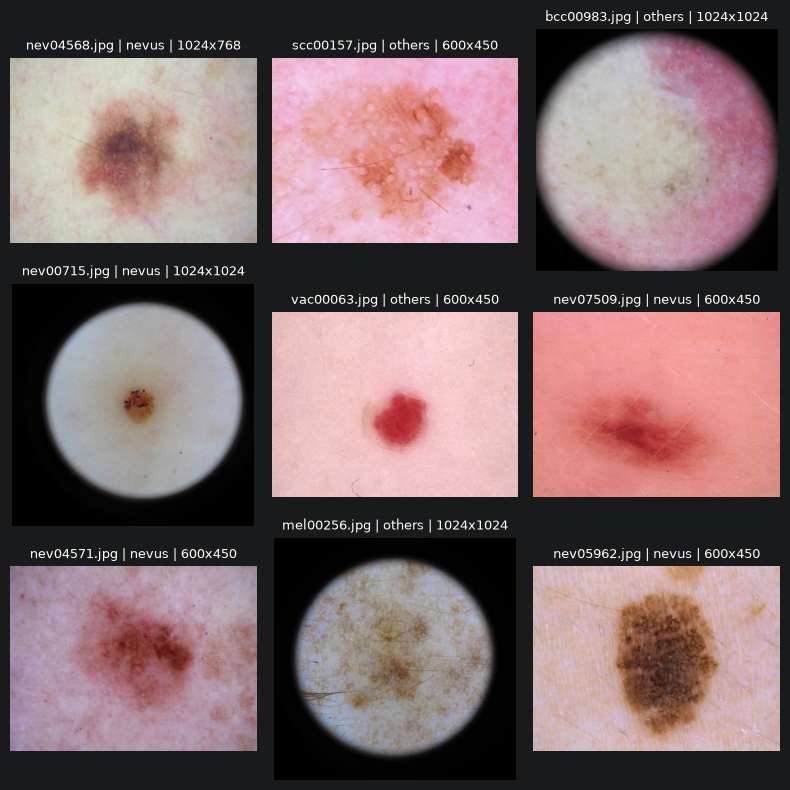

In [7]:
seed = np.random.randint(0, 1000)
print("seed:", seed)

sample = meta_data.sample(9, random_state=seed)

images, titles = [], []
for _, row in sample.iterrows():
    img = Image.open(BINARY_TRAIN_DIR / row["class"] / row["filename"])
    images.append(np.array(img))
    titles.append(f'{row["filename"]} | {row["class"]} | {row["width"]}x{row["height"]}')

show_grid(images, titles)

## Exploration of the additional features (regional and HoG)
Training images only (validation stays untouched). The same analysis is done for the binary problem
(base + regional + HoG) and for the multiclass problem (base + regional).

In [8]:
%load_ext autoreload
%autoreload 2
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score
from src.config import *
from src.utils import *
from src.experiments import CV, MULTI_SCORING

base = pd.read_csv(BINARY_FEATURES_TRAIN_FULL_CSV)
extra = pd.read_csv(BINARY_EXTRA_TRAIN_FULL_CSV)
binary = base.merge(extra.drop(columns="label"), on="filename")

base_cols = [c for c in base.columns if c not in ("filename", "label")]
reg_cols = [c for c in extra.columns if c.startswith("reg_")]
hog_cols = [c for c in extra.columns if c.startswith("hog_")]
groups = feature_groups(base_cols + reg_cols + hog_cols)
{name: len(cols) for name, cols in groups.items()}

{'colour moments': 36,
 'colour histograms': 96,
 'LBP': 80,
 'GLCM': 18,
 'reg. centre': 68,
 'reg. centre - periphery': 68,
 'reg. quadrant std': 68,
 'reg. asymmetry': 8,
 'HoG': 324}

### 1. Separation power of each feature family (binary)
For every feature, |AUC − 0.5| for nevus vs others (0 = no separation, 0.5 = perfect), summarised per family:
best feature, mean over the family, and how many of the 50 best features overall belong to it.

In [9]:
sep_binary = auc_separation(binary, base_cols + reg_cols + hog_cols)
separation_by_group(sep_binary, groups).round(3)

,features,best,mean,in top-50
colour moments,36.0,0.203,0.076,1.0
colour histograms,96.0,0.263,0.074,3.0
LBP,80.0,0.268,0.183,41.0
GLCM,18.0,0.179,0.062,0.0
reg. centre,68.0,0.219,0.102,1.0
reg. centre - periphery,68.0,0.226,0.127,4.0
reg. quadrant std,68.0,0.173,0.060,0.0
reg. asymmetry,8.0,0.064,0.040,0.0
HoG,324.0,0.166,0.071,0.0


In [10]:
group_of = {c: name for name, cols in groups.items() for c in cols}
top = sep_binary.nlargest(20)
pd.DataFrame({"family": top.index.map(group_of), "|AUC - 0.5|": top.round(3)})

,family,|AUC - 0.5|
lbp_P24_R5_6,LBP,0.268
lbp_P24_R5_5,LBP,0.265
hist_hsv_s_3,colour histograms,0.263
lbp_P24_R5_7,LBP,0.258
lbp_P24_R3_7,LBP,0.251
lbp_P24_R3_8,LBP,0.249
lbp_P24_R3_1,LBP,0.246
hist_hsv_s_4,colour histograms,0.245
lbp_P24_R5_8,LBP,0.242
lbp_P24_R3_9,LBP,0.241


### 2. Do the new features add information, or repeat the base features?
For every new feature, its highest |correlation| with any of the 230 base features.
Close to 1 means it mostly repeats a base feature; low values mean new information.

In [11]:
red = max_abs_correlation(binary, reg_cols + hog_cols, base_cols)
pd.DataFrame({name: {"median max |r|": red[cols].median(), "% with max |r| > 0.9": 100 * (red[cols] > 0.9).mean()}
              for name, cols in groups.items() if name.startswith(("reg.", "HoG"))}).T.round(2)

,median max |r|,% with max |r| > 0.9
reg. centre,0.86,27.94
reg. centre - periphery,0.50,0.00
reg. quadrant std,0.50,0.00
reg. asymmetry,0.30,0.00
HoG,0.28,0.00


### 3. Distributions of regional features
The 12 most separating regional features, and the 8 asymmetry features.

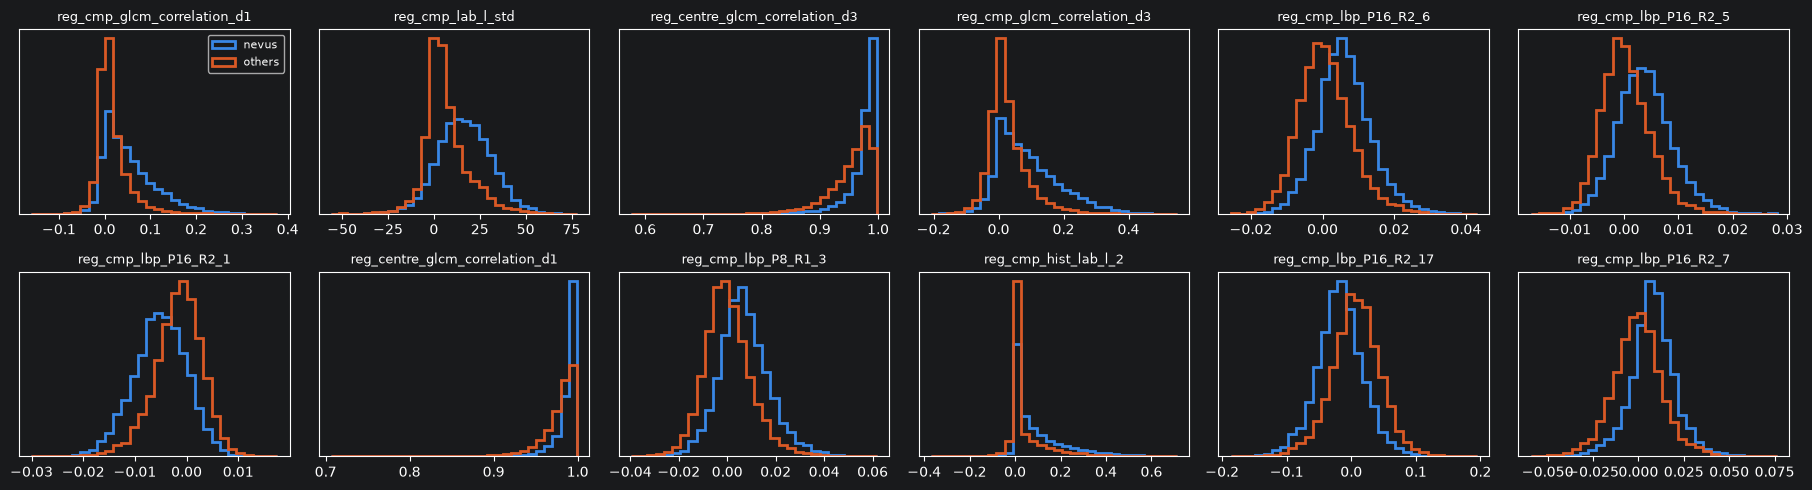

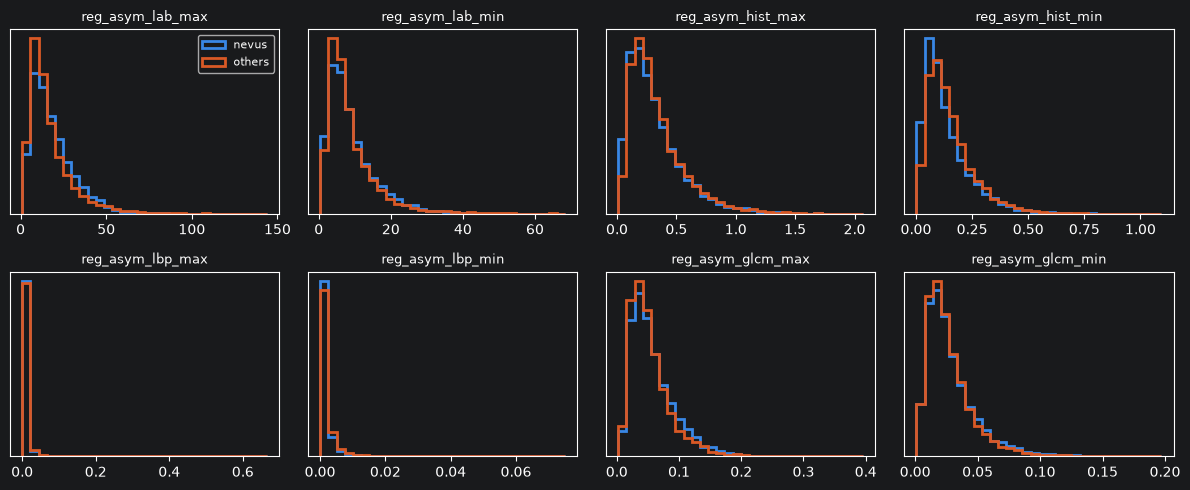

In [12]:
plot_feature_distributions(binary, sep_binary[reg_cols].nlargest(12).index.tolist())
plot_feature_distributions(binary, groups["reg. asymmetry"], ncols=4)

### 4. HoG features
Example images with their HoG (128×128, 32 px cells). The 324 values are 3×3 blocks × 2×2 cells × 9 orientations
(0–180°); averaging over blocks and cells gives one orientation profile per image.

seed: 688


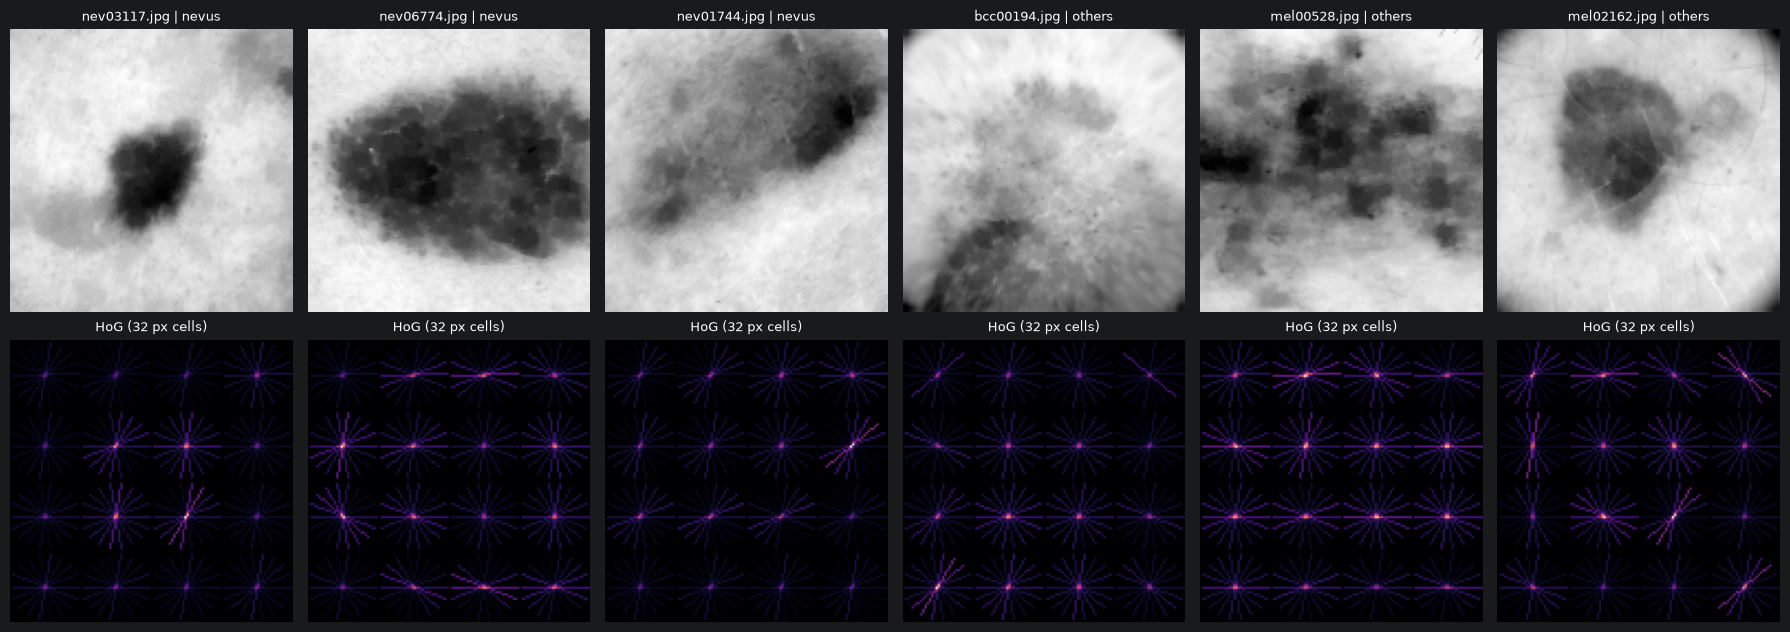

In [13]:
def hog_image(img, size=128, cell=32):
    """Grey image resized as in hog_features, and its HoG visualisation."""
    small = cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (size, size), interpolation=cv2.INTER_AREA)
    _, vis = hog(small, orientations=9, pixels_per_cell=(cell, cell), cells_per_block=(2, 2),
                 block_norm="L2-Hys", visualize=True)
    return small, vis

seed = np.random.randint(1000)
print("seed:", seed)
s = binary.groupby("label").sample(3, random_state=seed)

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for col, r in enumerate(s.itertuples()):
    small, vis = hog_image(load_preprocessed(r.filename, r.label, BINARY_PREPROC_TRAIN_DIR))
    axes[0, col].imshow(small, cmap="gray")
    axes[0, col].set_title(f"{r.filename} | {CLASS_NAMES[r.label]}", fontsize=9)
    axes[1, col].imshow(vis, cmap="magma")
    axes[1, col].set_title("HoG (32 px cells)", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

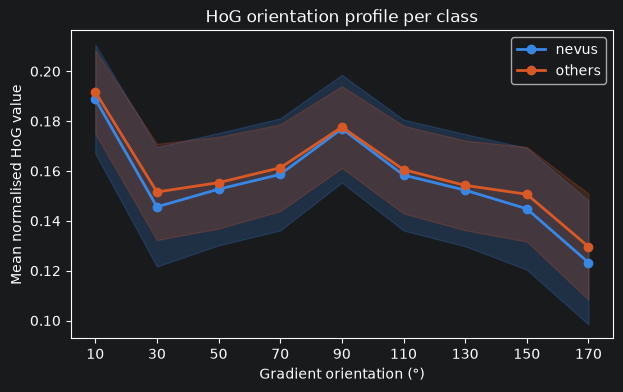

In [14]:
profile = binary[hog_cols].values.reshape(len(binary), 3, 3, 2, 2, 9).mean(axis=(1, 2, 3, 4))   # 9 values per image
angles = np.arange(10, 180, 20)                                                                  # bin centres (°)

fig, ax = plt.subplots(figsize=(7, 4))
for label, name in CLASS_NAMES.items():
    p = profile[binary["label"].values == label]
    mean, std = p.mean(axis=0), p.std(axis=0)
    ax.plot(angles, mean, "o-", color=CLASS_COLORS[label], linewidth=2, label=name)
    ax.fill_between(angles, mean - std, mean + std, color=CLASS_COLORS[label], alpha=0.2)
ax.set_xticks(angles)
ax.set_xlabel("Gradient orientation (°)")
ax.set_ylabel("Mean normalised HoG value")
ax.set_title("HoG orientation profile per class")
ax.legend()
plt.show()

### 5. PCA (3 components): base vs base + regional
PCA is unsupervised: it shows the directions of largest variance, which are not necessarily the ones that
separate the classes. The table below complements it with the CV score of a logistic regression trained on the
first k principal components.

In [15]:
pca_3d(binary, base_cols, "Binary - base")
pca_3d(binary, base_cols + reg_cols, "Binary - base + regional")

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",3
,"random_state random_state: int, RandomState instance or None, default=NoneUsed when the 'arpack' or 'randomized' solvers are used. Pass an intfor reproducible results across multiple function calls.See :term:`Glossary <random_state>`... versionadded:: 0.18.0",42
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to en

In [16]:
def pcs_score(df, sets, scoring, n_components=(3, 10, 30)):
    """CV score of a logistic regression trained on the first k principal components of each feature set."""
    rows = []
    for name, cols in sets.items():
        for k in n_components:
            pipe = make_pipeline(StandardScaler(), PCA(n_components=k, random_state=RANDOM_STATE),
                                 LogisticRegression(max_iter=2000))
            s = cross_val_score(pipe, df[cols].values, df["label"].values, cv=CV, scoring=scoring, n_jobs=-2)
            rows.append({"features": name, "principal components": k, "score": s.mean()})
    return pd.DataFrame(rows).pivot(index="features", columns="principal components", values="score").round(3)

SETS = {"base": base_cols, "base + regional": base_cols + reg_cols}
pcs_score(binary, SETS, scoring="balanced_accuracy")

principal components,3,10,30
features,,,
base,0.734,0.756,0.767
base + regional,0.741,0.762,0.778


### 6. Supervised view: out-of-fold LDA
Each image is projected by an LDA fitted on the other 4 folds, so the plot is not optimistic.
Binary: one LDA axis per image (histogram per class).

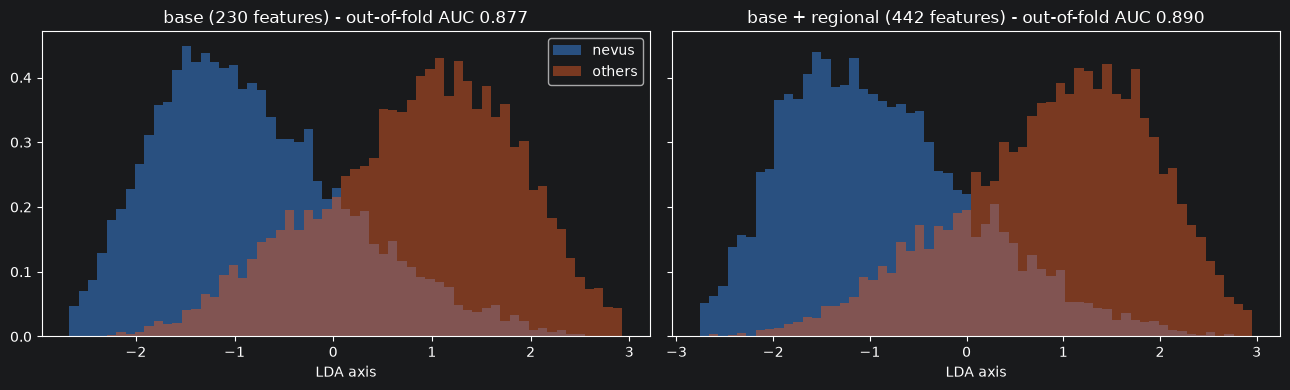

In [17]:
def oof_lda(X, y, cv=CV):
    """Out-of-fold LDA projection: each image is projected by an LDA fitted without it."""
    Z = np.zeros((len(y), len(np.unique(y)) - 1))
    for tr, te in cv.split(X, y):
        lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto"))
        lda.fit(X[tr], y[tr])
        sign = np.where(lda.transform(X[tr])[y[tr] == 0].mean(axis=0) > 0, -1, 1)   # same orientation in every fold
        Z[te] = lda.transform(X[te]) * sign
    return Z

y_b = binary["label"].values
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, cols) in zip(axes, SETS.items()):
    z = oof_lda(binary[cols].values, y_b).ravel()
    bins = np.linspace(np.percentile(z, 0.5), np.percentile(z, 99.5), 60)
    for label, cname in CLASS_NAMES.items():
        ax.hist(z[y_b == label], bins=bins, density=True, alpha=0.5, color=CLASS_COLORS[label], label=cname)
    ax.set_title(f"{name} ({len(cols)} features) - out-of-fold AUC {roc_auc_score(y_b, z):.3f}")
    ax.set_xlabel("LDA axis")
axes[0].legend()
plt.tight_layout()
plt.show()

### 7. Multiclass (mel / bcc / scc)
Same analysis on the multiclass training images (base + regional; HoG was not extracted for multiclass).
Separation is measured for each pair of classes; bcc vs scc is the pair the models confuse most.

In [18]:
multi = pd.read_csv(MULTI_FEATURES_TRAIN_CSV).merge(
    pd.read_csv(MULTI_REGIONAL_TRAIN_CSV).drop(columns="label"), on="filename")
mgroups = feature_groups(base_cols + reg_cols)

PAIRS = {"mel vs bcc": (0, 1), "mel vs scc": (0, 2), "bcc vs scc": (1, 2)}
pd.concat({pair: separation_by_group(auc_separation(multi, base_cols + reg_cols, pos=a, neg=b), mgroups)[["best", "mean"]]
           for pair, (a, b) in PAIRS.items()}, axis=1).round(3)

mel vs bcc        mel vs scc        bcc vs scc       
                              best   mean       best   mean       best   mean
colour moments               0.363  0.168      0.314  0.146      0.143  0.079
colour histograms            0.317  0.139      0.309  0.132      0.143  0.053
LBP                          0.245  0.070      0.180  0.049      0.115  0.034
GLCM                         0.289  0.244      0.276  0.153      0.131  0.105
reg. centre                  0.306  0.135      0.308  0.105      0.142  0.058
reg. centre - periphery      0.223  0.072      0.245  0.063      0.087  0.029
reg. quadrant std            0.235  0.073      0.195  0.064      0.116  0.031
reg. asymmetry               0.207  0.063      0.200  0.069      0.030  0.019

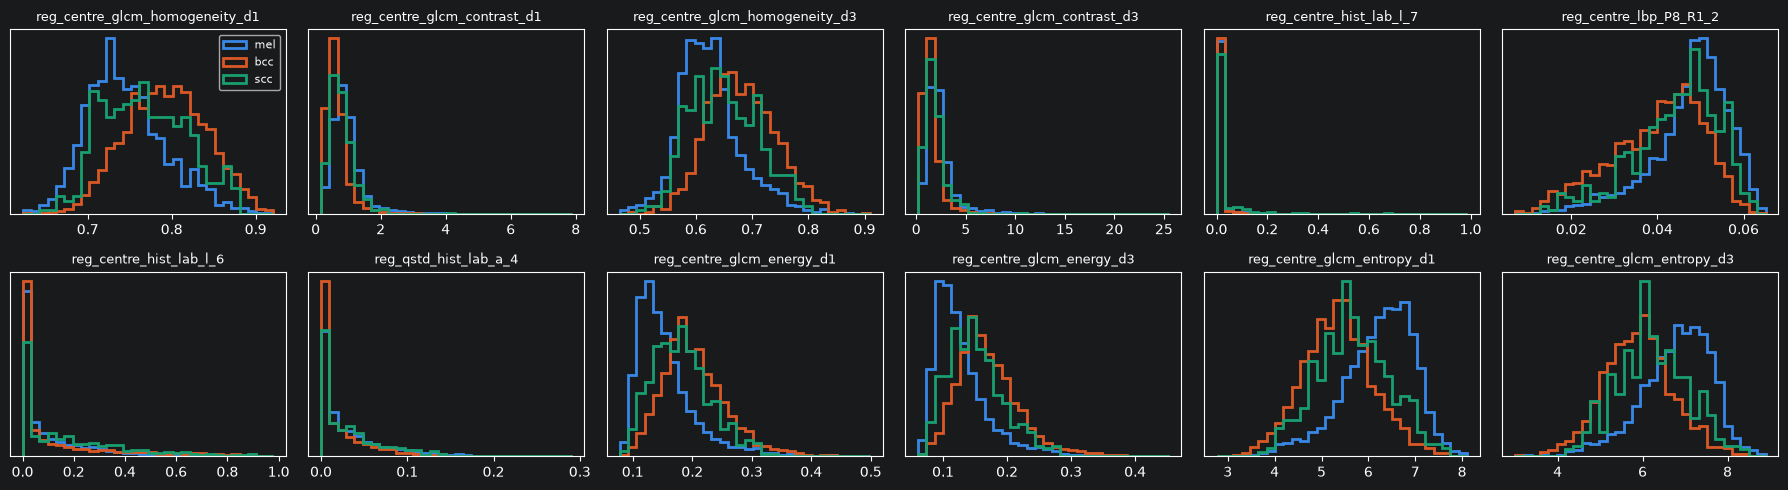

In [19]:
sep_bcc_scc = auc_separation(multi, reg_cols, pos=2, neg=1)
plot_feature_distributions(multi, sep_bcc_scc.nlargest(12).index.tolist(),
                           class_names=MULTI_CLASS_NAMES, class_colors=MULTI_CLASS_COLORS)

In [20]:
red_m = max_abs_correlation(multi, reg_cols, base_cols)
pd.DataFrame({name: {"median max |r|": red_m[cols].median(), "% with max |r| > 0.9": 100 * (red_m[cols] > 0.9).mean()}
              for name, cols in mgroups.items() if name.startswith("reg.")}).T.round(2)

,median max |r|,% with max |r| > 0.9
reg. centre,0.85,16.18
reg. centre - periphery,0.46,0.00
reg. quadrant std,0.47,0.00
reg. asymmetry,0.32,0.00


In [21]:
pca_3d(multi, base_cols, "Multiclass - base", MULTI_CLASS_NAMES, MULTI_CLASS_COLORS, n_points=len(multi))
pca_3d(multi, base_cols + reg_cols, "Multiclass - base + regional", MULTI_CLASS_NAMES, MULTI_CLASS_COLORS, n_points=len(multi))
pcs_score(multi, SETS, scoring=MULTI_SCORING["kappa"])

principal components,3,10,30
features,,,
base,0.484,0.564,0.589
base + regional,0.475,0.571,0.605


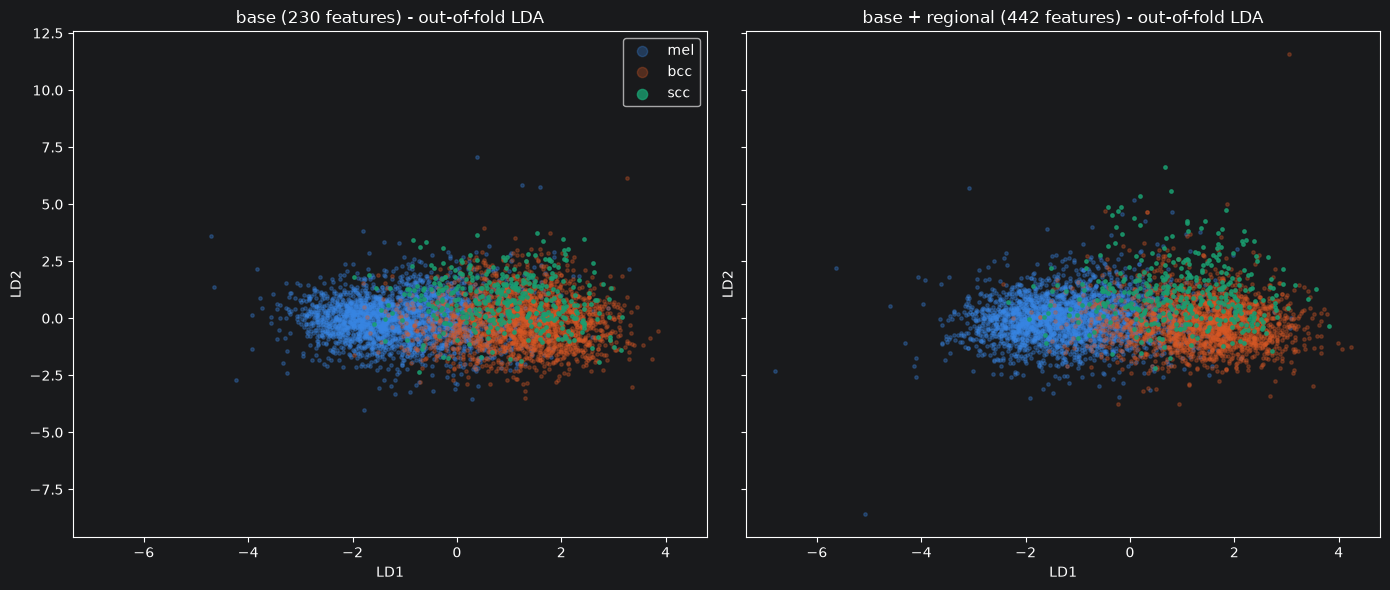

In [22]:
y_m = multi["label"].values
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, (name, cols) in zip(axes, SETS.items()):
    Z = oof_lda(multi[cols].values, y_m)
    for label, cname in MULTI_CLASS_NAMES.items():
        m = y_m == label
        ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.8 if cname == "scc" else 0.3,
                   color=MULTI_CLASS_COLORS[label], label=cname)
    ax.set_title(f"{name} ({len(cols)} features) - out-of-fold LDA")
    ax.set_xlabel("LD1")
    ax.set_ylabel("LD2")
axes[0].legend(markerscale=3)
plt.tight_layout()
plt.show()